# Lista 1 – Regressão Linear Múltipla

**0. Preparação do ambiente**

**1. Exercício 1 – Propagandas:** modelo de regressão múltipla para predizer as vendas (`Propagandas.csv`)
- 1.1. Análise descritiva
- 1.2. Correlação e covariância
- 1.3. Modelo de regressão
- 1.4. Análise de resíduos
- 1.5. Análise de multicolinearidade
- 1.6. Análise do modelo

**2. Exercício 2 – Preços de carros:** três modelos de regressão múltipla para predizer o preço dos automóveis (`Preços_Carros.csv`)
- 2.1. Análise descritiva
- 2.2. Correlação e covariância
- 2.3. Modelos de regressão
- 2.4. Análise de resíduos
- 2.5. Análise de multicolinearidade
- 2.6. Análise de outliers
- 2.7. Comparação de modelos

## 0. Preparação do ambiente

> **Objetivo:** importar as bibliotecas usadas no notebook.

In [22]:
# Importação das bibliotecas necessárias
import numpy as np # Para operações numéricas
import pandas as pd # Para manipulação de dados em DataFrame
import matplotlib.pyplot as plt # Para criação de gráficos
import seaborn as sns # Para visualização de dados estatísticos

sns.set_theme(style='whitegrid')

## 1. Exercício 1 – Propagandas

> **Objetivo:** predizer `Vendas` a partir do investimento em `TV`, `Radio` e `Jornal`.

### 1.1. Análise descritiva

> **Objetivo:** conhecer os dados antes de modelar.

#### 1.1.1. Carregamento dos dados

> **Objetivo:** carregar a base e ver como ela se apresenta.

In [23]:
propagandas = pd.read_csv('../data/Propagandas.csv')

Visualização das 5 primeiras linhas

In [24]:
propagandas.head()

,TV,Radio,Jornal,Vendas
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


#### 1.1.2. Dimensão da base de dados e tipo das variáveis

> **Objetivo:** saber o tamanho da base e se os tipos estão adequados.

In [25]:
print(f"Observações: {propagandas.shape[0]} | Variáveis: {propagandas.shape[1]}")
propagandas.dtypes

Observações: 200 | Variáveis: 4


TV        float64
Radio     float64
Jornal    float64
Vendas    float64
dtype: object

#### 1.1.3. Verificação de valores ausentes e linhas duplicadas

> **Objetivo:** verificar se a base precisa de limpeza.

In [26]:
print(f"Linhas duplicadas: {propagandas.duplicated().sum()}")
propagandas.isnull().sum()

Linhas duplicadas: 0


TV        0
Radio     0
Jornal    0
Vendas    0
dtype: int64

#### 1.1.4. Medidas de tendência central, dispersão e forma

> **Objetivo:** resumir em números o centro, a dispersão e a assimetria de cada variável.

In [27]:
resumo = propagandas.describe().T
resumo['CV (%)'] = propagandas.std() / propagandas.mean() * 100
resumo['assimetria'] = propagandas.skew()
resumo.round(2)

,count,mean,std,min,25%,50%,75%,max,CV (%),assimetria
TV,200.0,147.04,85.85,0.7,74.38,149.75,218.82,296.4,58.39,-0.07
Radio,200.0,23.26,14.85,0.0,9.98,22.90,36.52,49.6,63.82,0.09
Jornal,200.0,30.55,21.78,0.3,12.75,25.75,45.10,114.0,71.28,0.89
Vendas,200.0,14.02,5.22,1.6,10.38,12.90,17.40,27.0,37.21,0.41


#### 1.1.5. Comparação do coeficiente de variação

> **Objetivo:** comparar a dispersão relativa de variáveis com médias diferentes (CV = desvio padrão / média).

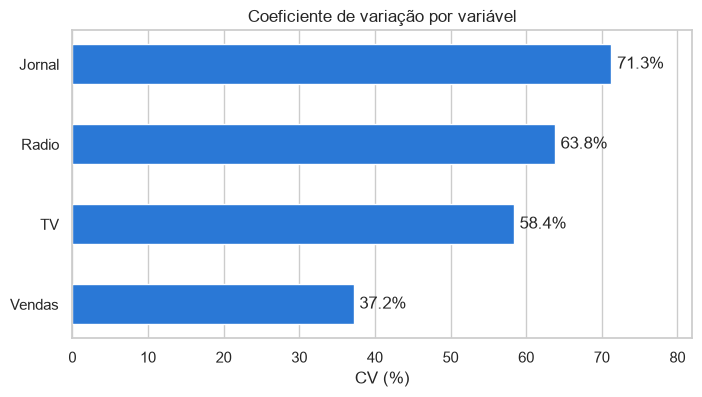

In [28]:
cv = resumo['CV (%)'].sort_values()

plt.figure(figsize=(8, 4))
barras = plt.barh(cv.index, cv.values, color='#2a78d6', height=0.5)
plt.bar_label(barras, fmt='%.1f%%', padding=4)
plt.title('Coeficiente de variação por variável')
plt.xlabel('CV (%)')
plt.xlim(0, cv.max() * 1.15)
plt.grid(axis='y', visible=False)
plt.show()

#### 1.1.6. Distribuição das variáveis

> **Objetivo:** ver o formato da distribuição (histograma) e possíveis outliers (boxplot) de cada variável.

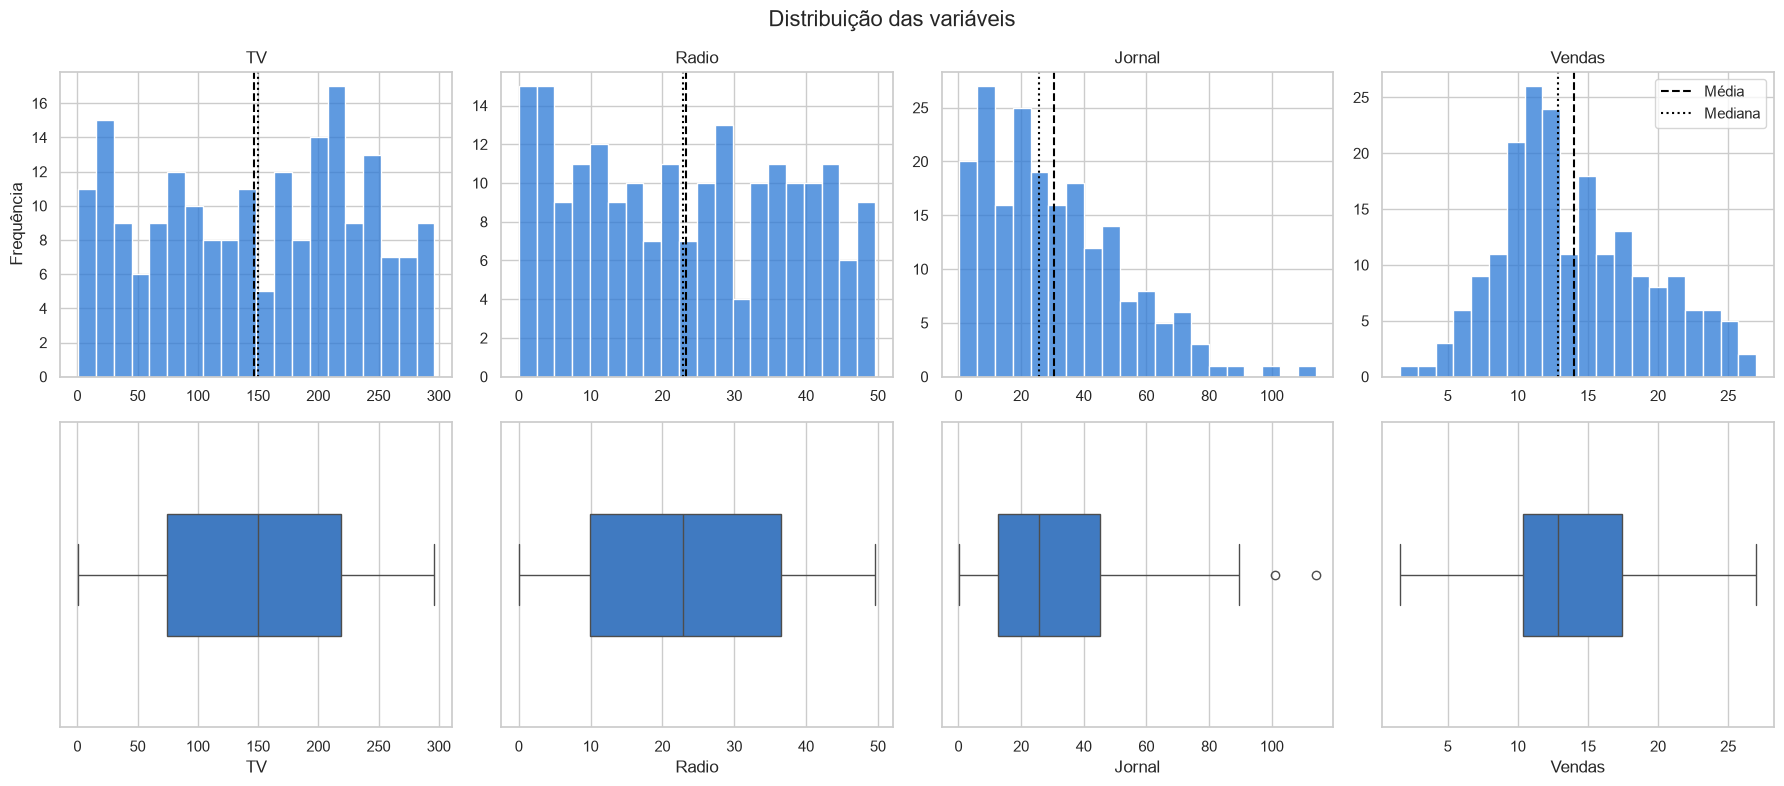

In [29]:
cor = '#2a78d6'
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for i, coluna in enumerate(propagandas.columns):
    # Histograma com as linhas de média e mediana
    sns.histplot(propagandas[coluna], bins=20, color=cor, ax=axes[0, i])
    axes[0, i].axvline(propagandas[coluna].mean(), color='black', linestyle='--', label='Média')
    axes[0, i].axvline(propagandas[coluna].median(), color='black', linestyle=':', label='Mediana')
    axes[0, i].set_title(coluna)
    axes[0, i].set_xlabel('')
    axes[0, i].set_ylabel('Frequência' if i == 0 else '')

    # Boxplot
    sns.boxplot(x=propagandas[coluna], color=cor, width=0.4, ax=axes[1, i])

axes[0, 3].legend()
fig.suptitle('Distribuição das variáveis', fontsize=16)
plt.tight_layout()
plt.show()

#### 1.1.7. Contagem de outliers pelo IQR

> **Objetivo:** contar e identificar os outliers, isto é, valores abaixo de Q1 - 1,5·IQR ou acima de Q3 + 1,5·IQR.

In [30]:
Q1 = propagandas.quantile(0.25)
Q3 = propagandas.quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR
mascara_outliers = (propagandas < limite_inferior) | (propagandas > limite_superior)

print("Outliers por variável:")
print(mascara_outliers.sum())

# Observações com pelo menos um outlier
propagandas[mascara_outliers.any(axis=1)]

Outliers por variável:
TV        0
Radio     0
Jornal    2
Vendas    0
dtype: int64


,TV,Radio,Jornal,Vendas
16,67.8,36.6,114.0,12.5
101,296.4,36.3,100.9,23.8


#### 1.1.8. Relação entre as variáveis

> **Objetivo:** ver, par a par, se as variáveis se relacionam e de que forma.

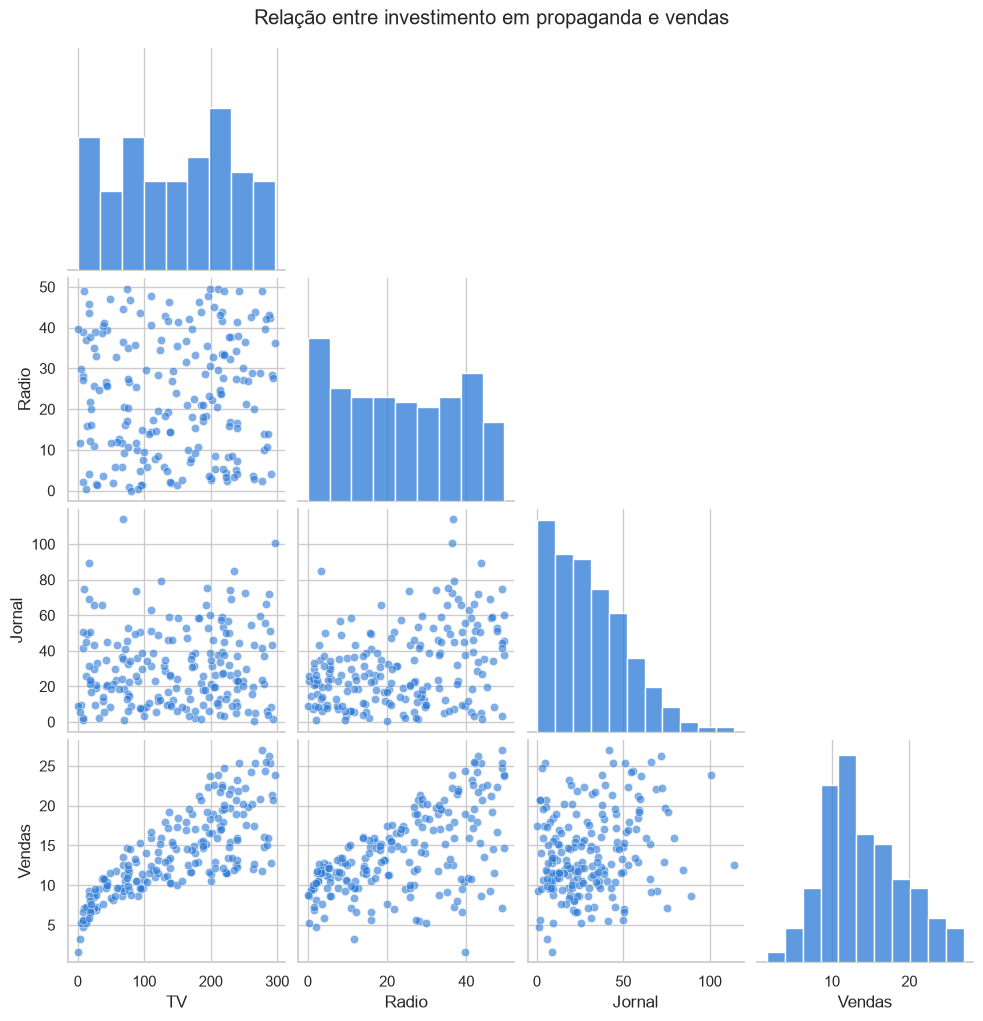

In [31]:
grafico = sns.pairplot(propagandas, corner=True, plot_kws={'color': cor, 'alpha': 0.6}, diag_kws={'color': cor})
grafico.figure.suptitle('Relação entre investimento em propaganda e vendas', y=1.02)
plt.show()

#### 1.1.9. Vendas x variáveis preditoras

> **Objetivo:** ver a direção e a força da relação de cada preditora com `Vendas`.

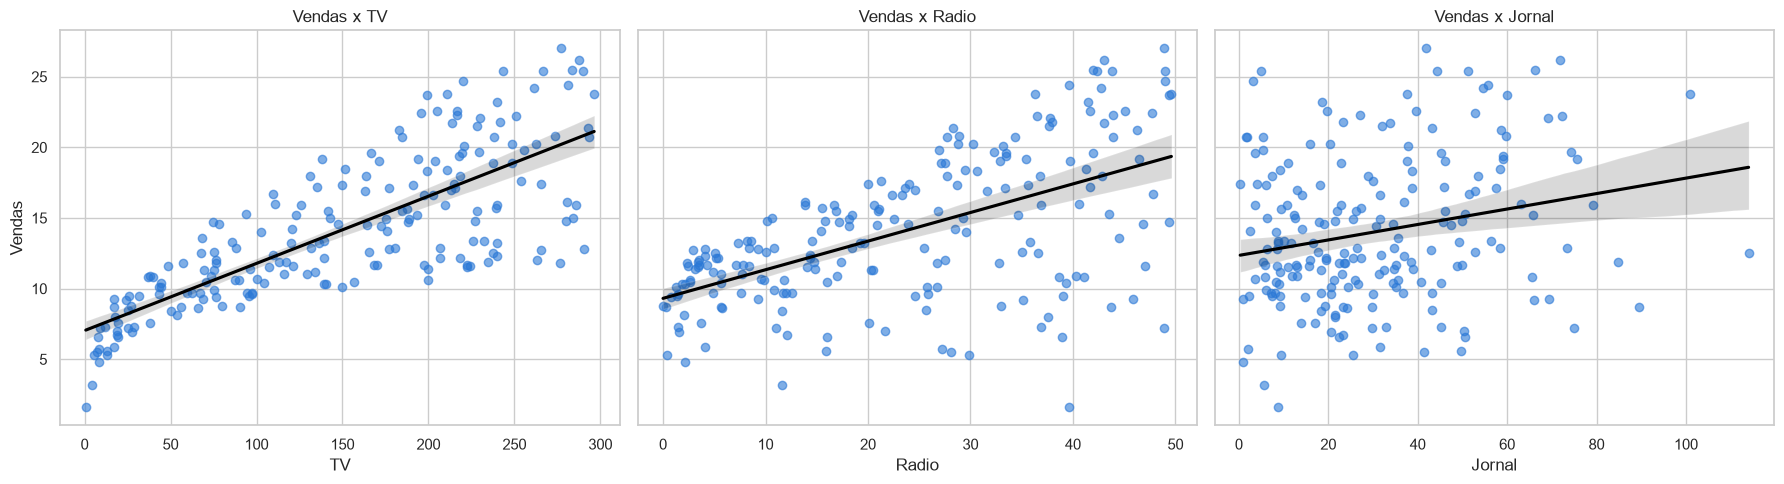

In [32]:
preditoras = ['TV', 'Radio', 'Jornal']
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, coluna in zip(axes, preditoras):
    sns.regplot(data=propagandas, x=coluna, y='Vendas', ax=ax,
                scatter_kws={'color': cor, 'alpha': 0.6}, line_kws={'color': 'black'})
    ax.set_title(f'Vendas x {coluna}')
    ax.set_ylabel('Vendas' if coluna == 'TV' else '')

plt.tight_layout()
plt.show()